<h1>Monstro da Semana 10: Devorador de Mentes</h1>

<h4><i>- Bruno Bini Camargo</i></h4>

Neste notebook serão resolvidas as situações $1$, $2$ e $3$ do monstro Devorador de Mentes.

Vamos criar uma função para concluir o teste de hipótese a partir do $p$-valor observado. A função foi retirada do material de aula "LMA-203 A.4 - Usando testes de hipóteses prontos usuais", do Prof. Dr. Daniel Cassar, para a disciplina de Probabilidade e Estatística, da Ilum Escola de Ciência $[1]$.

In [1]:
def conclusao(pvalor, significancia):

    print("p-valor =", pvalor)

    print()

    if pvalor < significancia:
        print("Conclusão do teste de hipótese: \033[31mdevemos rejeitar H0\033[0m")
    else:
        print("Conclusão do teste de hipótese: \x1b[32mnão devemos rejeitar H0\x1b[0m")

<h2>Situação 1</h2>

Uma notícia sobre a Ilum que saiu recentemente no jornal *Últimas Notícias* dizia que os estudantes desta instituição são muito dedicados e leem em torno de $10$ livros por ano. O que você pode dizer sobre essa afirmação?

Antes de iniciar a resolução da situação $1$, vamos importar os dados do Censo Ilum, que estão em uma planilha .xlsx, para o formato de `DataFrame` do `pandas`:

In [2]:
import pandas as pd

df = pd.read_excel("Censo Ilum.xlsx")

df.head()

,Qual é a sua altura em centímetros?,Qual é o número de sapato que você calça?,Qual o mês do seu aniversário?,Quantos irmãos você tem?,Quantos livros você leu no ano passado?,Quantas horas (em média) você dorme por noite?,Qual das opções abaixo melhor te representa?,"Das cores abaixo, qual é a sua favorita (ou a cor que mais gosta se sua cor favorita não estiver na lista)?",Qual a sua opinião sobre azeitona?,Cachorros ou gatos?,Escolha um número aleatório entre 0 e 100
0,160.0,35.0,5,1,34.0,NaN,NaN,Amarelo,4.0,Gatos!,NaN
1,167.0,36.0,8,1,18.0,7.0,Sou destro,Amarelo,1.0,Cachorros!,22.0
2,168.0,37.0,3,1,11.0,6.0,Sou destro,Amarelo,1.0,Cachorros!,84.0
3,169.0,39.0,9,2,8.0,NaN,NaN,Amarelo,3.0,Gatos!,NaN
4,170.0,36.0,7,0,42.0,6.0,Sou destro,Amarelo,5.0,Cachorros!,23.0


A variável de interesse é o número de livros lidos no ano passado, correspondente à coluna "Quantos livros você leu no ano passado?". Antes de realizar qualquer teste estatístico, é necessário verificar a qualidade dos dados e obter uma visão geral da distribuição observada. Por isso, vamos calcular as estatísticas descritivas da variável:

In [3]:
livros = df["Quantos livros você leu no ano passado?"].dropna()

livros.describe()

count    129.000000
mean      10.472868
std       12.998845
min        0.000000
25%        4.000000
50%        7.000000
75%       12.000000
max      110.000000
Name: Quantos livros você leu no ano passado?, dtype: float64

Observa-se que a média amostral foi de aproximadamente $10.47$ livros por ano, valor bastante próximo da hipótese proposta pela reportagem ($10$ livros por ano). Entretanto, a mediana observada foi de apenas $7$ livros, um tanto quanto inferior à média. Essa diferença sugere a presença de assimetria à direita na distribuição, possivelmente causada por estudantes que relataram quantidades muito elevadas de leitura.

Além disso, o valor máximo observado foi de $110$ livros, enquanto $75\%$ dos estudantes relataram ter lido até $12$ livros no ano anterior. Essa grande diferença indica a possível existência de valores extremos (*outliers*) que tendem a puxar a média para cima. O desvio padrão também se mostrou elevado ($\approx 13$ livros), evidenciando grande variabilidade entre os participantes da pesquisa.

Analisemos a distribuição do número de livros lidos e um boxplot:

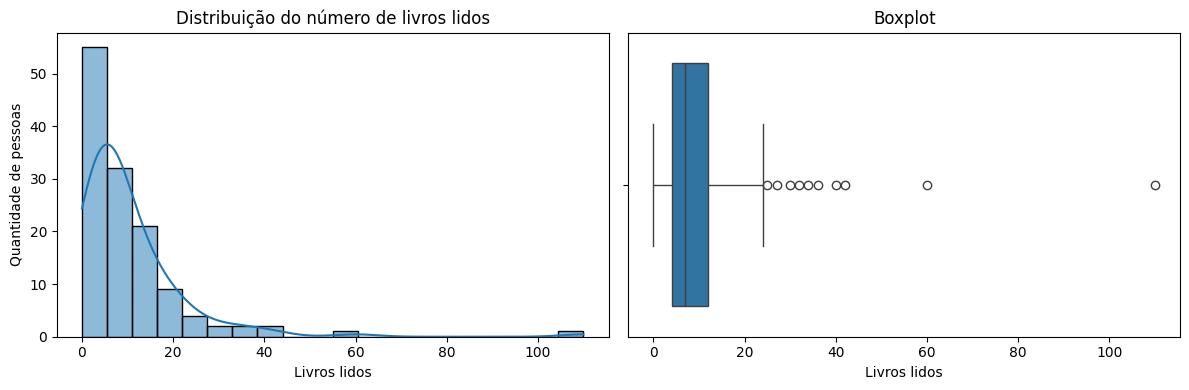

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(livros, bins=20, kde=True, ax=ax[0])
ax[0].set_title("Distribuição do número de livros lidos")
ax[0].set_xlabel("Livros lidos")
ax[0].set_ylabel("Quantidade de pessoas")

sns.boxplot(x=livros, ax=ax[1])
ax[1].set_title("Boxplot")
ax[1].set_xlabel("Livros lidos")

plt.tight_layout()
plt.show()

Observa-se uma distribuição fortemente assimétrica à direita (como já sugerida pelas estatísticas descritivas), caracterizada pela concentração da maior parte das observações em valores relativamente baixos e pela presença de uma cauda longa em direção aos valores mais elevados.

O boxplot confirma a presença de diversos valores discrepantes (*outliers*), incluindo observações acima de $40$ livros e um valor extremo de $110$ livros. Apesar disso, esses registros correspondem a respostas plausíveis e, portanto, foram mantidos na análise.

Após essa análise exploratória, faremos o teste de hipótese. Nossas hipóteses de teste são:
- $H_0$: $\mu = 10$
- $H_1$: $\mu \neq 10$

Assim, com base nisso, o teste escolhido para essa análise foi o **teste t de Student para uma amostra**. Essa escolha se justifica pelo fato de que o objetivo da análise é verificar se a média populacional do número de livros lidos pelos estudantes da Ilum é compatível com o valor de referência de $10$ livros por ano apresentado pela reportagem.

Embora a análise exploratória tenha indicado uma distribuição assimétrica à direita e a presença de alguns valores extremos, a amostra possui $129$ observações. Dessa forma, o tamanho amostral pode ser considerado suficientemente grande para que o Teorema do Limite Central ($\text{TLC}$) seja aplicado. Pelo $\text{TLC}$, à medida que o tamanho da amostra aumenta, a distribuição da média amostral tende a se aproximar de uma distribuição normal, mesmo quando os dados originais não seguem perfeitamente essa distribuição.

Assim, apesar dos desvios observados em relação à normalidade dos dados individuais, a utilização do teste t permanece apropriada para realizar inferências sobre a média populacional.

Adotou-se um nível de significância de $5\%$ ($\alpha = 0.05$). Dessa forma, a hipótese nula será rejeitada caso o $p$-valor obtido seja inferior a $0.05$.

In [5]:
from scipy.stats import ttest_1samp

t_stat, p_valor = ttest_1samp(livros, popmean=10)

print(f"Estatística t = {t_stat:.4f}")

conclusao(p_valor, 0.05)

Estatística t = 0.4132
p-valor = 0.6801723922628724

Conclusão do teste de hipótese: não devemos rejeitar H0


A aplicação do teste t de Student para uma amostra resultou em uma estatística de teste igual a $t=0.4132$ e $p$-valor de $0.6802$. Considerando o nível de significância de $5\%$, não rejeitamos a hipótese nula, uma vez que o $p$-valor é superior ao valor de significância adotado.

Portanto, não foram encontradas evidências estatísticas suficientes para afirmar que a média de livros lidos pelos estudantes da Ilum difere de $10$ livros por ano. Assim, os resultados são compatíveis com a afirmação apresentada pela reportagem, embora não permitam comprovar que a média populacional seja exatamente igual a esse valor.

<h2>Situação 2</h2>

O podcast sobre ciência *Devaneios Probabilísticos* discutiu recentemente um artigo que dizia que pessoas cujo número aleatório escolhido é menor que $50$ tendem a dormir mais horas por noite do que pessoas cujo número aleatório escolhido é maior ou igual a $50$. O que você pode dizer sobre essa afirmação considerando os dados do Censo Ilum?

Primeiramente, vamos separar os dados:

In [6]:
col_numero = "Escolha um número aleatório entre 0 e 100"
col_sono = "Quantas horas (em média) você dorme por noite?"

grupo_menor50 = df[df[col_numero] < 50].dropna()
grupo_maior50 = df[df[col_numero] >= 50].dropna()

sono_menor50 = grupo_menor50[col_sono]
sono_maior50 = grupo_maior50[col_sono]

Antes da realização do teste de hipótese, vamos fazer uma análise exploratória dos dois grupos para compreender o comportamento dos dados e identificar possíveis diferenças entre eles.

In [7]:
print(sono_menor50.describe())
print()
print(sono_maior50.describe())

count    37.000000
mean     11.970541
std      17.223358
min       4.000000
25%       7.000000
50%       7.000000
75%       8.000000
max      75.000000
Name: Quantas horas (em média) você dorme por noite?, dtype: float64

count    26.000000
mean     16.911538
std      24.247133
min       6.000000
25%       6.125000
50%       7.000000
75%       7.000000
max      75.000000
Name: Quantas horas (em média) você dorme por noite?, dtype: float64


O grupo de participantes com número aleatório inferior a $50$ apresentou média de $11.97$ horas de sono por noite, enquanto o grupo com número aleatório maior ou igual a $50$ apresentou média de $16.91$ horas. Entretanto, essas médias são significativamente superiores ao esperado para padrões normais de sono, sugerindo a presença de *outliers*.

Além disso, os desvios padrão observados foram bastante elevados ($17.22$ e $24.25$ horas, respectivamente), enquanto as medianas foram de $7$ horas em ambos os grupos. Essa discrepância entre médias e medianas reforça a hipótese de que valores extremos estão exercendo forte influência sobre as estatísticas calculadas.

Dessa forma, vamos investigar os possíveis *outliers* presentes na variável de horas de sono.

Como um dia possui apenas $24$ horas, valores superiores a esse limite são incompatíveis com a variável analisada e podem ser interpretados como erros de preenchimento ou digitação.

Para identificar essas observações, utilizaremos o seguinte filtro:

In [8]:
df[
    df["Quantas horas (em média) você dorme por noite?"] > 24
][["Quantas horas (em média) você dorme por noite?"]]

,Quantas horas (em média) você dorme por noite?
32,75.0
40,75.0
56,65.0
92,75.0
124,75.0
126,55.0
135,75.0


Foram identificados registros correspondentes a $55$, $65$ e $75$ horas de sono por noite. Como esses valores são fisicamente impossíveis, eles foram considerados inconsistências na base de dados.

A manutenção dessas observações poderia distorcer significativamente as médias, desvios padrão e os resultados dos testes estatísticos. Portanto, esses registros serão removidos antes da continuidade da análise.

In [9]:
df_limpo = df[
    df["Quantas horas (em média) você dorme por noite?"] <= 24
].copy()

Com a remoção dos *outliers*, vamos recriar os grupos:

In [10]:
grupo_menor50_limpo = df_limpo[
    df_limpo[col_numero] < 50
]

grupo_maior50_limpo = df_limpo[
    df_limpo[col_numero] >= 50
]

sono_menor50_limpo = grupo_menor50_limpo[col_sono]
sono_maior50_limpo = grupo_maior50_limpo[col_sono]

Reanalisemos as estatísticas descritivas dos grupos:

In [11]:
print(sono_menor50_limpo.describe())
print()
print(sono_maior50_limpo.describe())

count    36.000000
mean      6.941944
std       1.110943
min       4.000000
25%       6.000000
50%       7.000000
75%       7.000000
max       9.000000
Name: Quantas horas (em média) você dorme por noite?, dtype: float64

count    27.000000
mean      6.840741
std       0.868358
min       6.000000
25%       6.000000
50%       7.000000
75%       7.000000
max      10.000000
Name: Quantas horas (em média) você dorme por noite?, dtype: float64


É possível perceber que os dados apresentam valores plausíveis, apresentando médias e medianas de aproximadamente $7$ horas de sono por noite. 

Agora sim analisemos o boxplot:

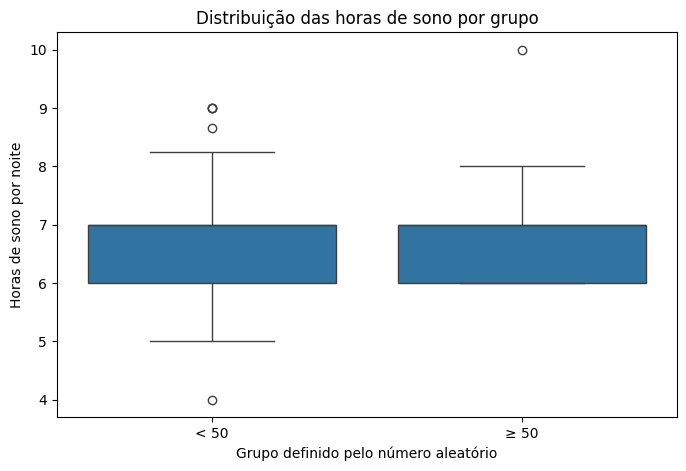

In [12]:
plot_df = df_limpo[[col_numero, col_sono]].copy()

plot_df["Grupo"] = plot_df[col_numero].apply(
    lambda x: "< 50" if x < 50 else "≥ 50"
)

plt.figure(figsize=(8,5))

sns.boxplot(
    data=plot_df,
    x="Grupo",
    y=col_sono
)

plt.title("Distribuição das horas de sono por grupo")
plt.xlabel("Grupo definido pelo número aleatório")
plt.ylabel("Horas de sono por noite")

plt.show()

Observa-se que a maior parte dos participantes de ambos os grupos relata dormir aproximadamente entre $6$ e $7$ horas por noite. As distribuições apresentam comportamento semelhante e não exibem diferenças visuais expressivas entre os grupos.

Visualmente, não se observa uma separação clara entre as distribuições dos grupos. Portanto, a análise gráfica por si só não é suficiente para sustentar ou refutar a afirmação apresentada pelo podcast, sendo necessária a realização de um teste de hipótese para avaliar formalmente a existência de diferença entre as médias.

Vamos definir primeiro as hipóteses do teste:

- $H_0$: $\mu_{<50} \geq \mu_{\geq50}$
- $H_1$: $\mu_{<50} <\mu_{\geq50}$
  
Como o objetivo é comparar a média de uma variável quantitativa (horas de sono) entre dois grupos independentes de participantes, foi utilizado o **teste t de Welch para duas amostras independentes**. 
Por se tratar de uma hipótese direcional, foi considerado um teste unilateral, uma vez que o objetivo é verificar especificamente se participantes com número aleatório inferior a $50$ dormem mais ou a mesma quantidade de horas por noite do que participantes com número aleatório maior ou igual a $50$.

Adotou-se um nível de significância de $5\%$. Dessa forma, a hipótese nula será rejeitada caso o $p$-valor obtido seja inferior a $0.05$.

In [13]:
from scipy.stats import ttest_ind

t, p_valor = ttest_ind(
    sono_menor50_limpo,
    sono_maior50_limpo,
    equal_var=False,
    alternative="less"
)

print(f"Estatística t = {t:.4f}")
conclusao(p_valor, 0.05)

Estatística t = 0.4058
p-valor = 0.6568272327935016

Conclusão do teste de hipótese: não devemos rejeitar H0


A aplicação do teste t de Welch para duas amostras independentes resultou em uma estatística de teste igual a $t=0.4058$ e $p$-valor unilateral de $0.6568$. Considerando o nível de significância de $5\%$, não rejeitamos a hipótese nula, uma vez que o $p$-valor obtido é superior ao valor de significância adotado.

Portanto, não foram encontradas evidências estatísticas suficientes para rejeitar a afirmação de que participantes que escolheram números inferiores a $50$ dormem mais horas por noite do que aqueles que escolheram números maiores ou iguais a $50$.

<h2>Situação 3</h2>

Recentemente viralizou no *Y* a notícia de que a altura média de quem prefere as cores Azul, Roxo, Rosa, Verde e Preto é igual. O que você pode dizer sobre essa afirmação considerando os dados do Censo Ilum?


Primeiramente, vamos selecionar apenas os participantes cuja cor favorita corresponde a uma das cinco cores mencionadas na notícia.

In [14]:
cores = ["Azul", "Roxo", "Rosa", "Verde", "Preto"]

cor_col = "Das cores abaixo, qual é a sua favorita (ou a cor que mais gosta se sua cor favorita não estiver na lista)?"
altura_col = "Qual é a sua altura em centímetros?"

df_cores = (
    df[[cor_col, altura_col]]
    .dropna()
)

df_cores = df_cores[
    df_cores[cor_col].isin(cores)
]

df_cores.head()

,"Das cores abaixo, qual é a sua favorita (ou a cor que mais gosta se sua cor favorita não estiver na lista)?",Qual é a sua altura em centímetros?
8,Azul,1.79
9,Azul,154.00
10,Azul,158.00
11,Azul,158.00
12,Azul,160.00


Antes de analisar as alturas, é interessante verificar a quantidade de participantes em cada grupo.

In [15]:
df_cores[cor_col].value_counts()

Das cores abaixo, qual é a sua favorita (ou a cor que mais gosta se sua cor favorita não estiver na lista)?
Azul     44
Roxo     23
Preto    17
Verde    14
Rosa      8
Name: count, dtype: int64

Observamos que os grupos possuem tamanhos amostrais distintos. Essa diferença deve ser considerada durante a interpretação dos resultados, em especial para grupos com menor número de observações.

Vejamos as estatísticas descritivas:

In [16]:
df_cores.groupby(cor_col)[altura_col].describe()

,count,mean,std,min,25%,50%,75%,max
"Das cores abaixo, qual é a sua favorita (ou a cor que mais gosta se sua cor favorita não estiver na lista)?",,,,,,,,
Azul,44.0,166.767955,26.948260,1.79,162.00,170.5,177.00,195.0
Preto,17.0,253.235294,332.952048,153.00,169.00,174.0,178.00,1545.0
Rosa,8.0,165.375000,8.975164,153.00,161.50,162.5,168.75,182.0
Roxo,23.0,170.130435,11.302873,153.00,162.50,167.0,176.50,193.0
Verde,14.0,154.214286,40.521938,17.00,155.25,163.0,171.50,181.0


Analisando as estatísticas descritivas, é possível perceber que os valores mínimos e máximos fornecem indicação da existência de *outliers*, uma vez que há alturas incompatíveis com valores plausíveis para seres humanos.

Para identificar esses registros:

In [17]:
df_cores[
    (df_cores[altura_col] < 100)
    |
    (df_cores[altura_col] > 250)
][[cor_col, altura_col]]

,"Das cores abaixo, qual é a sua favorita (ou a cor que mais gosta se sua cor favorita não estiver na lista)?",Qual é a sua altura em centímetros?
8,Azul,1.79
73,Preto,1545.00
105,Verde,17.00


Foram identificados registros com alturas inferiores a $100$ cm ou superiores a $250$ cm. Considerando que a população analisada é composta por estudantes universitários, tais valores são sugestivos de erros de preenchimento ou digitação. 
Essas observações podem exercer influência excessiva sobre medidas como média e desvio padrão, além de impactarem significativamente o teste de hipótese.
Para evitar que erros de preenchimento influenciem os resultados, esses registros serão removidos da análise.

In [18]:
df_cores_limpo = df_cores[
    (df_cores[altura_col] >= 100)
    &
    (df_cores[altura_col] <= 250)
].copy()

Após a remoção das observações inconsistentes, os dados passam a representar de maneira mais adequada as alturas dos participantes analisados, reduzindo o impacto de possíveis erros de coleta. 
Agora podemos visualizar a distribuição das alturas em cada grupo:

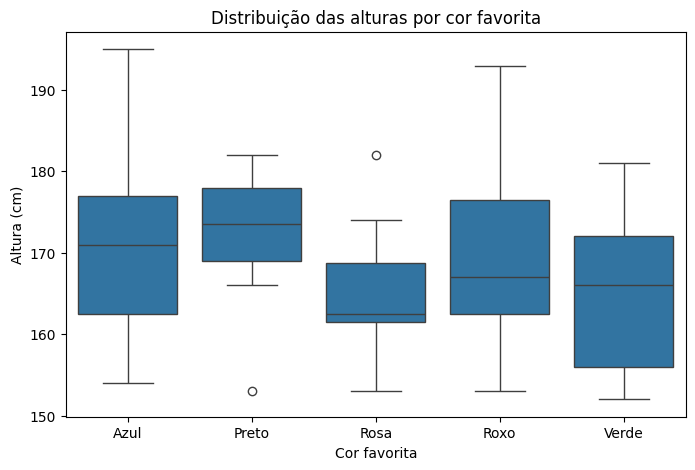

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

sns.boxplot(
    data=df_cores_limpo,
    x=cor_col,
    y=altura_col
)

plt.title("Distribuição das alturas por cor favorita")
plt.xlabel("Cor favorita")
plt.ylabel("Altura (cm)")

plt.show()

O boxplot permite avaliar diferenças nas medianas e na dispersão dos dados. Além disso, fornece uma primeira indicação sobre a existência (ou não) de diferenças aparentes entre as alturas médias associadas a cada cor favorita.

Por fim, é interessante recalcular as estatísticas após a remoção dos valores inconsistentes.

In [20]:
df_cores_limpo.groupby(cor_col)[altura_col].describe()

,count,mean,std,min,25%,50%,75%,max
"Das cores abaixo, qual é a sua favorita (ou a cor que mais gosta se sua cor favorita não estiver na lista)?",,,,,,,,
Azul,43.0,170.604651,8.965913,154.0,162.5,171.0,177.00,195.0
Preto,16.0,172.500000,7.146095,153.0,169.0,173.5,178.00,182.0
Rosa,8.0,165.375000,8.975164,153.0,161.5,162.5,168.75,182.0
Roxo,23.0,170.130435,11.302873,153.0,162.5,167.0,176.50,193.0
Verde,13.0,164.769231,9.444168,152.0,156.0,166.0,172.00,181.0


Com os dados tratados, observa-se uma representação mais fiel das alturas dos participantes. Observa-se que as médias dos grupos variam aproximadamente entre $165$ cm e $173$ cm.

Agora podemos seguir para o teste de hipótese. As hipóteses consideradas são:

- $H_0$: $\mu_{Azul} = \mu_{Roxo} = \mu_{Rosa} = \mu_{Verde} = \mu_{Preto}$
- $H_1$: pelo menos uma das médias difere das demais

Nesse contexto, como desejamos comparar as alturas médias de mais de dois grupos independentes, utilizaremos uma **Análise de Variância de uma Via (*One-Way ANOVA*)**. Esse teste avalia se as diferenças observadas entre as médias amostrais podem ser explicadas apenas pela variabilidade natural dos dados ou se existem evidências de diferenças reais entre as alturas médias dos grupos analisados.

Entretanto, antes de realizar o teste, é necessário analisar se o conjunto de dados obedece aos requisitos da *ANOVA* de homocedasticidade (homogeneidade na variância) e de normalidade. 

Para o teste de homocedasticidade, foi utilizado o teste de Levene. As hipóteses consideradas foram:

- $H_0$: as variâncias dos grupos são iguais
- $H_1$: pelo menos uma das variâncias difere das demais
  
Foi adotado nível de significância de $5\%$.

In [21]:
from scipy.stats import levene

estatistica_levene, p_levene = levene(
    *[
        grupo[altura_col].values
        for _, grupo in df_cores_limpo.groupby(cor_col)
    ],
    center="median"
)

print(f"Estatística de Levene = {estatistica_levene:.4f}")

conclusao(p_levene, 0.05)

Estatística de Levene = 1.2956
p-valor = 0.2771023584626473

Conclusão do teste de hipótese: não devemos rejeitar H0


O teste de Levene não forneceu evidências para rejeitar a hipótese de homogeneidade das variâncias. Dessa forma, o pressuposto de homocedasticidade pode ser considerado razoável para os grupos analisados, permitindo a aplicação da *ANOVA*.

Agora é necessário avaliar a normalidade dos dados. Para verificar essa condição, foi utilizado o teste de Shapiro-Wilk em cada um dos grupos considerados.

As hipóteses avaliadas foram:

- $H_0$: os dados seguem distribuição normal
- $H_1$: os dados não seguem distribuição normal

Adotou-se nível de significância de $5\%$.

In [22]:
from scipy.stats import shapiro

for cor, grupo in df_cores_limpo.groupby(cor_col):
    estatistica, p_valor = shapiro(grupo[altura_col])

    print(f"\nCor: {cor}")
    print(f"Estatística = {estatistica:.4f}")

    conclusao(p_valor, 0.05)


Cor: Azul
Estatística = 0.9651
p-valor = 0.21221803585402038

Conclusão do teste de hipótese: não devemos rejeitar H0

Cor: Preto
Estatística = 0.9041
p-valor = 0.09352517440475974

Conclusão do teste de hipótese: não devemos rejeitar H0

Cor: Rosa
Estatística = 0.9306
p-valor = 0.5213944965542905

Conclusão do teste de hipótese: não devemos rejeitar H0

Cor: Roxo
Estatística = 0.9627
p-valor = 0.5208024217540017

Conclusão do teste de hipótese: não devemos rejeitar H0

Cor: Verde
Estatística = 0.9298
p-valor = 0.33920297370236696

Conclusão do teste de hipótese: não devemos rejeitar H0


O teste de Shapiro-Wilk não forneceu evidências suficientes para rejeitar a hipótese de normalidade em nenhum dos grupos analisados. 
Dessa forma, o pressuposto de normalidade pode ser considerado razoável para os dados, permitindo a aplicação da *ANOVA*.
 
Iniciando a *ANOVA*, o primeiro passo é separar as alturas de cada grupo.

In [23]:
from scipy.stats import f_oneway

azul = df_cores_limpo[
    df_cores_limpo[cor_col] == "Azul"
][altura_col]

roxo = df_cores_limpo[
    df_cores_limpo[cor_col] == "Roxo"
][altura_col]

rosa = df_cores_limpo[
    df_cores_limpo[cor_col] == "Rosa"
][altura_col]

verde = df_cores_limpo[
    df_cores_limpo[cor_col] == "Verde"
][altura_col]

preto = df_cores_limpo[
    df_cores_limpo[cor_col] == "Preto"
][altura_col]

Em seguida, aplicamos a ANOVA.

Adotou-se nível de significância de $5\%$, de forma que, se $p < 0.05$, rejeitamos $H_0$ e, se $p \geq 0.05$, não rejeitamos $H_0$.

In [24]:
f_stat, p_valor = f_oneway(
    azul,
    roxo,
    rosa,
    verde,
    preto
)

print(f"Estatística F = {f_stat:.4f}")

conclusao(p_valor, 0.05)

Estatística F = 1.7985
p-valor = 0.13524949248563123

Conclusão do teste de hipótese: não devemos rejeitar H0


A aplicação da *ANOVA* resultou em uma estatística de teste igual a $F=1.7985$ e $p$-valor$=0.1352$. 
Considerando o nível de significância de $5%$, observa-se que o $p$-valor obtido é superior ao nível de significância adotado. Portanto, não há evidências estatísticas suficientes para rejeitar a hipótese de que as alturas médias dos participantes que preferem as cores Azul, Roxo, Rosa, Verde e Preto são iguais.

<h2>Interação com a IA</h2>

A inteligência artificial generativa foi utilizada ao longo do projeto como ferramenta de apoio na parte da programação, resolvendo dúvidas de sintaxe e realizando correções de erros de código (*debugging*). Além disso, foi também utilizada na revisão final dos testes de hipótese realizados.

<h2>Referências</h2>

$[1]$ CASSAR, Daniel R. **Notebooks Jupyter e materiais didáticos da disciplina de Probabilidade e Estatística**. Ilum Escola de Ciência, 2026.